# ComCon Vignette 1.2: Single-Species Workflow Using Manual Mode

**The same single-species analysis from Vignette 1.1, using Manual Mode**

---

## What This Vignette Covers

This vignette reproduces the same connectivity analysis from Vignette 1.1, a single-species study of *Patella vulgata* (common limpet) along the southern English coast but using **Manual Mode** instead of **Interactive Mode**.

By the end, you will have:

- Run the full 6-step workflow using Manual Mode's wrapper functions
- Calculated Type 1 connectivity metrics (settlement success, mortality, dispersal distances and local recruitment)
- Understood the differences between Interactive and Manual Mode

### Why Manual Mode?

ComCon offers three modes for running analyses. Interactive Mode guides you through each step with prompts and explanations. Manual Mode gives you direct access to the same underlying functions, which is useful when you want to:

- Have coding and modelling experience
- Build custom workflows that skip or repeat specific steps
- Test different parameters quickly by changing function arguments
- Integrate ComCon into larger analysis pipelines

The wrapper functions used here (e.g. `params()`, `spp_occ()`, `setup_release_settlement()`) still include interactive prompts for things like Copernicus credentials and species selection. The difference is that you call them explicitly rather than stepping through a guided workflow.

### What You Will Need

- ComCon installed in a Conda environment (see the User Guide, Part 1)
- A free Copernicus Marine Service account ([register here](https://data.marine.copernicus.eu/register))
- Approximately 2 hours (including simulation time)

### Why *Patella vulgata*?

<img src="patella_vulgata.jpg" alt="Patella vulgata on rocky shore" style="max-width: 600px; width: 100%;">

*Photo: Patella vulgata on a rocky shore in south-west England. Credit: Laura Bachmaier*

*P. vulgata* is an ideal starting species for several reasons. It is one of the most common rocky shore species in the NE Atlantic, making it well-studied with easily accessible trait data. Its short pelagic larval duration (PLD; 2–10 days) means the simulation will run quickly.

*P. vulgata* is a keystone grazer on NE Atlantic intertidal rocky shores, found from northern Norway to the Mediterranean. It is found on any hard substratum including rocks, stones and in rock pools, with higher abundances in wave exposed conditions. 

Spawning is annual, occurring October to January in southern England (though timing varies with latitude), with eggs and sperm broadcast into the water column. Spawning has been found to be triggered by heavy wave action and onshore winds. The planktotrophic trochophore larvae spend 2–10 days in the plankton before settling onto rocky substrate. Individuals typically have a life span of 11 to 20 years. 

This species is considered a keystone species in NE Atlantic rocky shores, having been found to significantly structure their surrounding ecological communities through their grazing behaviour, specifically fucoid and barnacle cover. Therefore, understanding *P. vulgata's* dispersal throughout its range and which populations are connected is important for predicting how entire rocky shore communities may shift under current and future stressors as well as to identify sites whose protection would benefit the wider network.

For further biological information see the full MarLIN species profile: https://www.marlin.ac.uk/species/detail/1371

<table style="text-align: left; margin-left: 0;">
  <thead>
    <tr>
      <th>Trait</th>
      <th>Value</th>
      <th>Source</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>Spawning season</td>
      <td>October – January</td>
      <td>MarLin (Hill, 2008)</td>
    </tr>
    <tr>
      <td>Minimum PLD</td>
      <td>2 days</td>
      <td>MarLin (Hill, 2008)</td>
    </tr>
    <tr>
      <td>Maximum PLD</td>
      <td>10 days</td>
      <td>MarLin (Hill, 2008)</td>
    </tr>
    <tr>
      <td>Habitat</td>
      <td>Rocky intertidal (coastal)</td>
      <td>—</td>
    </tr>
  </tbody>
</table>

### Research Questions
Each ComCon vignette addresses a different type of ecological question using the same underlying simulation framework:

**Vignette 1** (this vignette):

→ **Type 1: Connectivity Metrics**
- What are the general dispersal characteristics of *P. vulgata* along the southern English coast? For example:
    - How many larvae successfully settle?
    - How far do they travel?
    - Are populations self-sustaining through local recruitment or do they depend on larval supply from elsewhere?

**Vignette 2:** 

→ **Type 2: Network Analysis**
- Which sites are most important for maintaining connectivity across the community?
- Where are the connectivity hotspots, stepping stones and key source populations?
- Where are critical sink populations dependent on external larval supply?

**Vignette 3:** 

→ **Type 3: Trait Sensitivity Analysis**
- Which connectivity hotspots are robust to trait uncertainty and which are fragile?
- Do species-specific dispersal traits significantly shape connectivity patterns or are patterns primarily driven by oceanographic currents and coastal geography?
- What happens to the connectivity network if spawning windows shift (e.g. under climate change)?

### Before You Begin

A few things to note as you work through this vignette:
 
- Several functions include interactive prompts (marked with `[I]` in the function list). These will ask you to enter values such as Copernicus credentials, species selections and study area boundaries.
    - The values to enter at each prompt are explained in the text before each code cell, matching Vignette 1.1 exactly.
- File paths and folder locations will depend on your own computer setup. Wherever the vignette shows a file path, yours will be different. Just make sure you know where your working directory is.
- Saving prompts: ComCon will occasionally ask whether you want to save outputs (e.g., "Do you want to export the data to a NetCDF file?") or review parameters. These prompts are not described in detail below as the choices depend on your preferences. When in doubt, the defaults (shown in square brackets) are a safe choice.
- Parameter files: ComCon automatically saves your settings to JSON files (e.g., hydrodynamic_parameters.json) so you can reload them later without re-entering everything. This is useful if you need to restart your analysis.

### Getting Started

Open a new notebook in Jupyter Lab and make sure your `comcon` environment is active (you should see `(comcon)` in your terminal). If you need help with this, see the User Guide, Part 1.

Import ComCon by running the cell below. You will see the ComCon welcome message and the option to select your mode.

When the mode selection appears, choose Manual Mode and click Start.

You will see a message explaining Manual Mode.

---


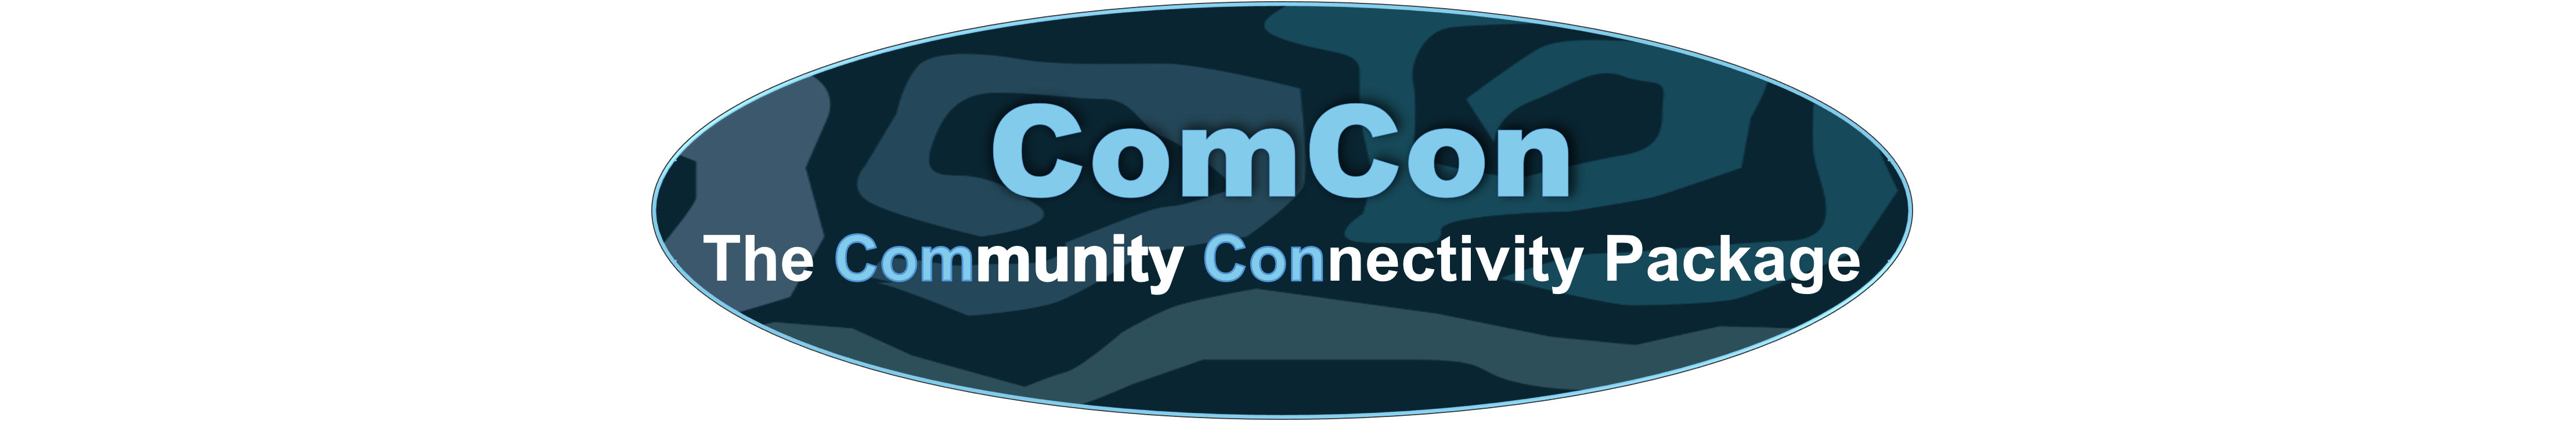


Welcome to ComCon!

This package facilitates multi-species dispersal modeling using Lagrangian particle tracking with Ocean Parcels and NEMO hydrodynamic data.

You can use the package in three modes:
  1. Interactive Mode: Step-by-step guided workflow
  2. Automatic Mode: Run entire workflow with preset parameters
  3. Manual Mode: Access individual functions for custom workflows



Please select a mode below:


Dropdown(description='Mode:', options=(('Interactive Mode', 'interactive'), ('Automatic Mode', 'automatic'), (…

Button(button_style='success', description='Start', icon='check', style=ButtonStyle())

Output(layout=Layout(height='0px', overflow='hidden'))

In [1]:
import comcon

In [2]:
from comcon.manual import *

> **Tip:** To see all available functions, run `list_functions()`. To see example workflows, run `example_workflow()`.

---

## Step 1: Hydrodynamic and Trait Data

This step collects your Copernicus Marine Service credentials, hydrodynamic extent, species trait data and the start year for the dispersal season. It then downloads the hydrodynamic data.

The `params()` function will prompt you for:

**Loading hydrodynamic data**
- Select Option 1: Download from Copernicus Marine Service

**Copernicus credentials:**
- Username and password for your Copernicus Marine Service account

**Dataset selection:**
- Use dataset ID: `cmems_mod_nws_phy-cur_anfc_1.5km-2D_PT1H-i`

For this example we will assess the connectivity of P. vulgata across its distribution in the south-west of the English Channel (Devon and Cornwall). Therefore we are using the Atlantic - European North West Shelf - Ocean Physics Analysis and Forecast hydrodyanmic model. This model has a spatial resolution of ~1.5km, uses surface (2D) data only and has an hourly temporal resolution.

**Hydrodynamic extent:**
- Longitude range: -7 to 2 
- Latitude range: 48 to 52 

Remember that the spatial extent of your hydrodynamic data needs to be much larger than your actual study area for which you are assessing connectivity of a given species. The hydrodynamic extent is the entire area in which your propagules can disperse not just settle within. Therefore, choosing an area on the generously bigger side is a safer bet in case some of your propagules travel very large distances.

**Species traits:**
- When asked for a trait source, choose **Built-in database**
- Select *Patella vulgata* from the database
- The trait values (spawning Oct–Jan, PLD 2–10 days) will be loaded automatically

**Temporal buffer:**
- Enter 0 for both (not needed for this basic analysis)

**Saving the hydrodynamic data:**

When prompted, you will have the option to either **export** the data to a **NetCDF** file on your computer or load it directly into your Python environment using **lazy loading**. 

- We recommend choosing **lazy loading** (i.e., selecting "no" when asked whether to export to NetCDF)

Lazy loading streams the data from the Copernicus servers as needed rather than downloading the entire file to your hard drive first. This is faster, avoids creating very large files on your computer (hydrodynamic datasets can be several gigabytes) and is how we run all the examples in these vignettes. The data will remain available in your `hydro_data` variable for the rest of the workflow or until you re-start the Kernel. 

If you do choose to export the data as a NetCDF file, be aware that the download can take a long time depending on the size of your study area, the length of the simulation period and your internet connection speed. For reference, the single species example in this vignette can take up to several hours to download as a NetCDF file. The advantage of saving to file is that you can reload the data later without re-downloading, which is useful if you plan to re-run the same analysis multiple times or need the data for other analyses.


**Simulation year:**
- Choose 2024 as the start year of this simulation

  
ComCon will calculate that the simulation needs to run from 1 October 2024 to approximately 10 February 2025 (spawning end + maximum PLD). It will then download the hydrodynamic data from Copernicus. This may take several minutes depending on your internet connection.

---

Now run the next cell, to set your parameters:

In [6]:
# Step 1a: Collect all parameters

hydro_params, species_traits_path, runtime, traits = params()

Found existing parameters. Do you want to reuse them? (yes/no):  no


Setting up the Hydrodynamic Extent



  Important: The hydrodynamic domain needs to be larger than your study area.



Enter your username:  lbachmaier
Enter your password:  ········
Enter the dataset ID:  cmems_mod_nws_phy-cur_anfc_1.5km-2D_PT1H-i
Enter the minimum longitude:  -7
Enter the maximum longitude:  2
Enter the minimum latitude:  48
Enter the maximum latitude:  52


Species Traits Data



How would you like to provide species traits data?
  1. Select species from builtin trait database
  2. Provide your own CSV file


... (16 outputs left out)


Add temporal buffer? (yes/no) [default: no]:  


No buffer added. Trait sensitivity analysis will not be possible.
Simulation period: 132
Runtime (in days): 132 days


Do you want to export the data to a NetCDF file? (yes/no):  no

Do you want to review and edit the parameters before saving? (yes/no):  no



Parameters have been saved to 'hydrodynamic_parameters.json'.


Now use the `download_hydrodynamic_data()` function to load the hydrodynamic data using the parameters collected above. This may take several minutes depending on your internet connection. 

In [7]:
# Step 1b: Download hydrodynamic data from Copernicus

hydro_data = download_hydrodynamic_data(**hydro_params)

INFO - 2026-02-23T15:50:57Z - Selected dataset version: "202511"
INFO:Selected dataset version: "202511"
INFO - 2026-02-23T15:50:57Z - Selected dataset part: "default"
INFO:Selected dataset part: "default"


---

## Step 2: Species Occurrence Data

ComCon needs to know where your species is found so it can set up appropriate release and settlement locations. The `spp_occ()` function handles the entire species occurrence workflow: downloading records from GBIF, creating habitat masks and filtering the data to your study area.

**What ComCon will ask you:**

**Study area polygon:**
- When prompted, draw a polygon on the interactive map covering the southern English coast, similar to the one drawn below in the example

<img src="study_area.jpg" alt="Study area selection of the South-West of England" style="max-width: 600px; width: 100%;">

*Photo: Study area selection of the South-West of England.*

This polygon defines where you want to focus your connectivity analysis. Alternatively, you can load an existing GeoJSON file, if you have one.

**Data source:**
- Choose GBIF

ComCon will search GBIF for *Patella vulgata* records within your study area.

**Habitat filtering:**
- Choose Coastal

This is appropriate for intertidal species like limpets. ComCon will create land and coastal masks from the hydrodynamic data and filter out any occurrence records that fall on land or in the open ocean.

You will see a summary showing how many records were downloaded and how many remain after data cleaning. A visualisation will display the filtered occurrence points on a map.

> **Tip:** If you have your own species distribution data (e.g., from field surveys), you can upload it as a CSV file instead of using GBIF. See the User Guide, Part 5 for the required CSV format.

Found existing parameters. Do you want to reuse them? (yes/no):  no


Select your study area



  This package requires a polygon of your study area in GeoJSON file format.
  
  You can either upload your own file or use the package functionality to select your study area on a map.




Do you want to use an existing GeoJSON file? (yes/no):  no

Do you want to save the species occurrence data as a CSV file? (yes/no):  no


Defining your study area



  You will be prompted to draw a polygon defining your study area.
  
  Important: Study area vs Hydrodynamic domain
  
  Hydrodynamic domain (already set):
    - The dispersal area
    - Large area where ocean currents are simulated
    - Particles can disperse throughout this entire region
  
  Study area (current step):
    - The focus area
    - Smaller, focused region of interest
    - Where particles will be released from
    - Where particle can settle to
    - Should fit comfortably within the hydrodynamic domain



... (5 outputs left out)


Selected: GBIF data

You have two options for downloading GBIF species occurrence data:

1. Download occurrences for specific species from your trait database
  - Recommended for connectivity analysis

2. Download all species in your study area
  - For exploratory analysis only as trait data will be missing



Choose mode (1 or 2) [default: 1]:  1




  [1/1] patella vulgata...

Downloaded 2261 occurrence records




Visualising the Hydrodynamic Data


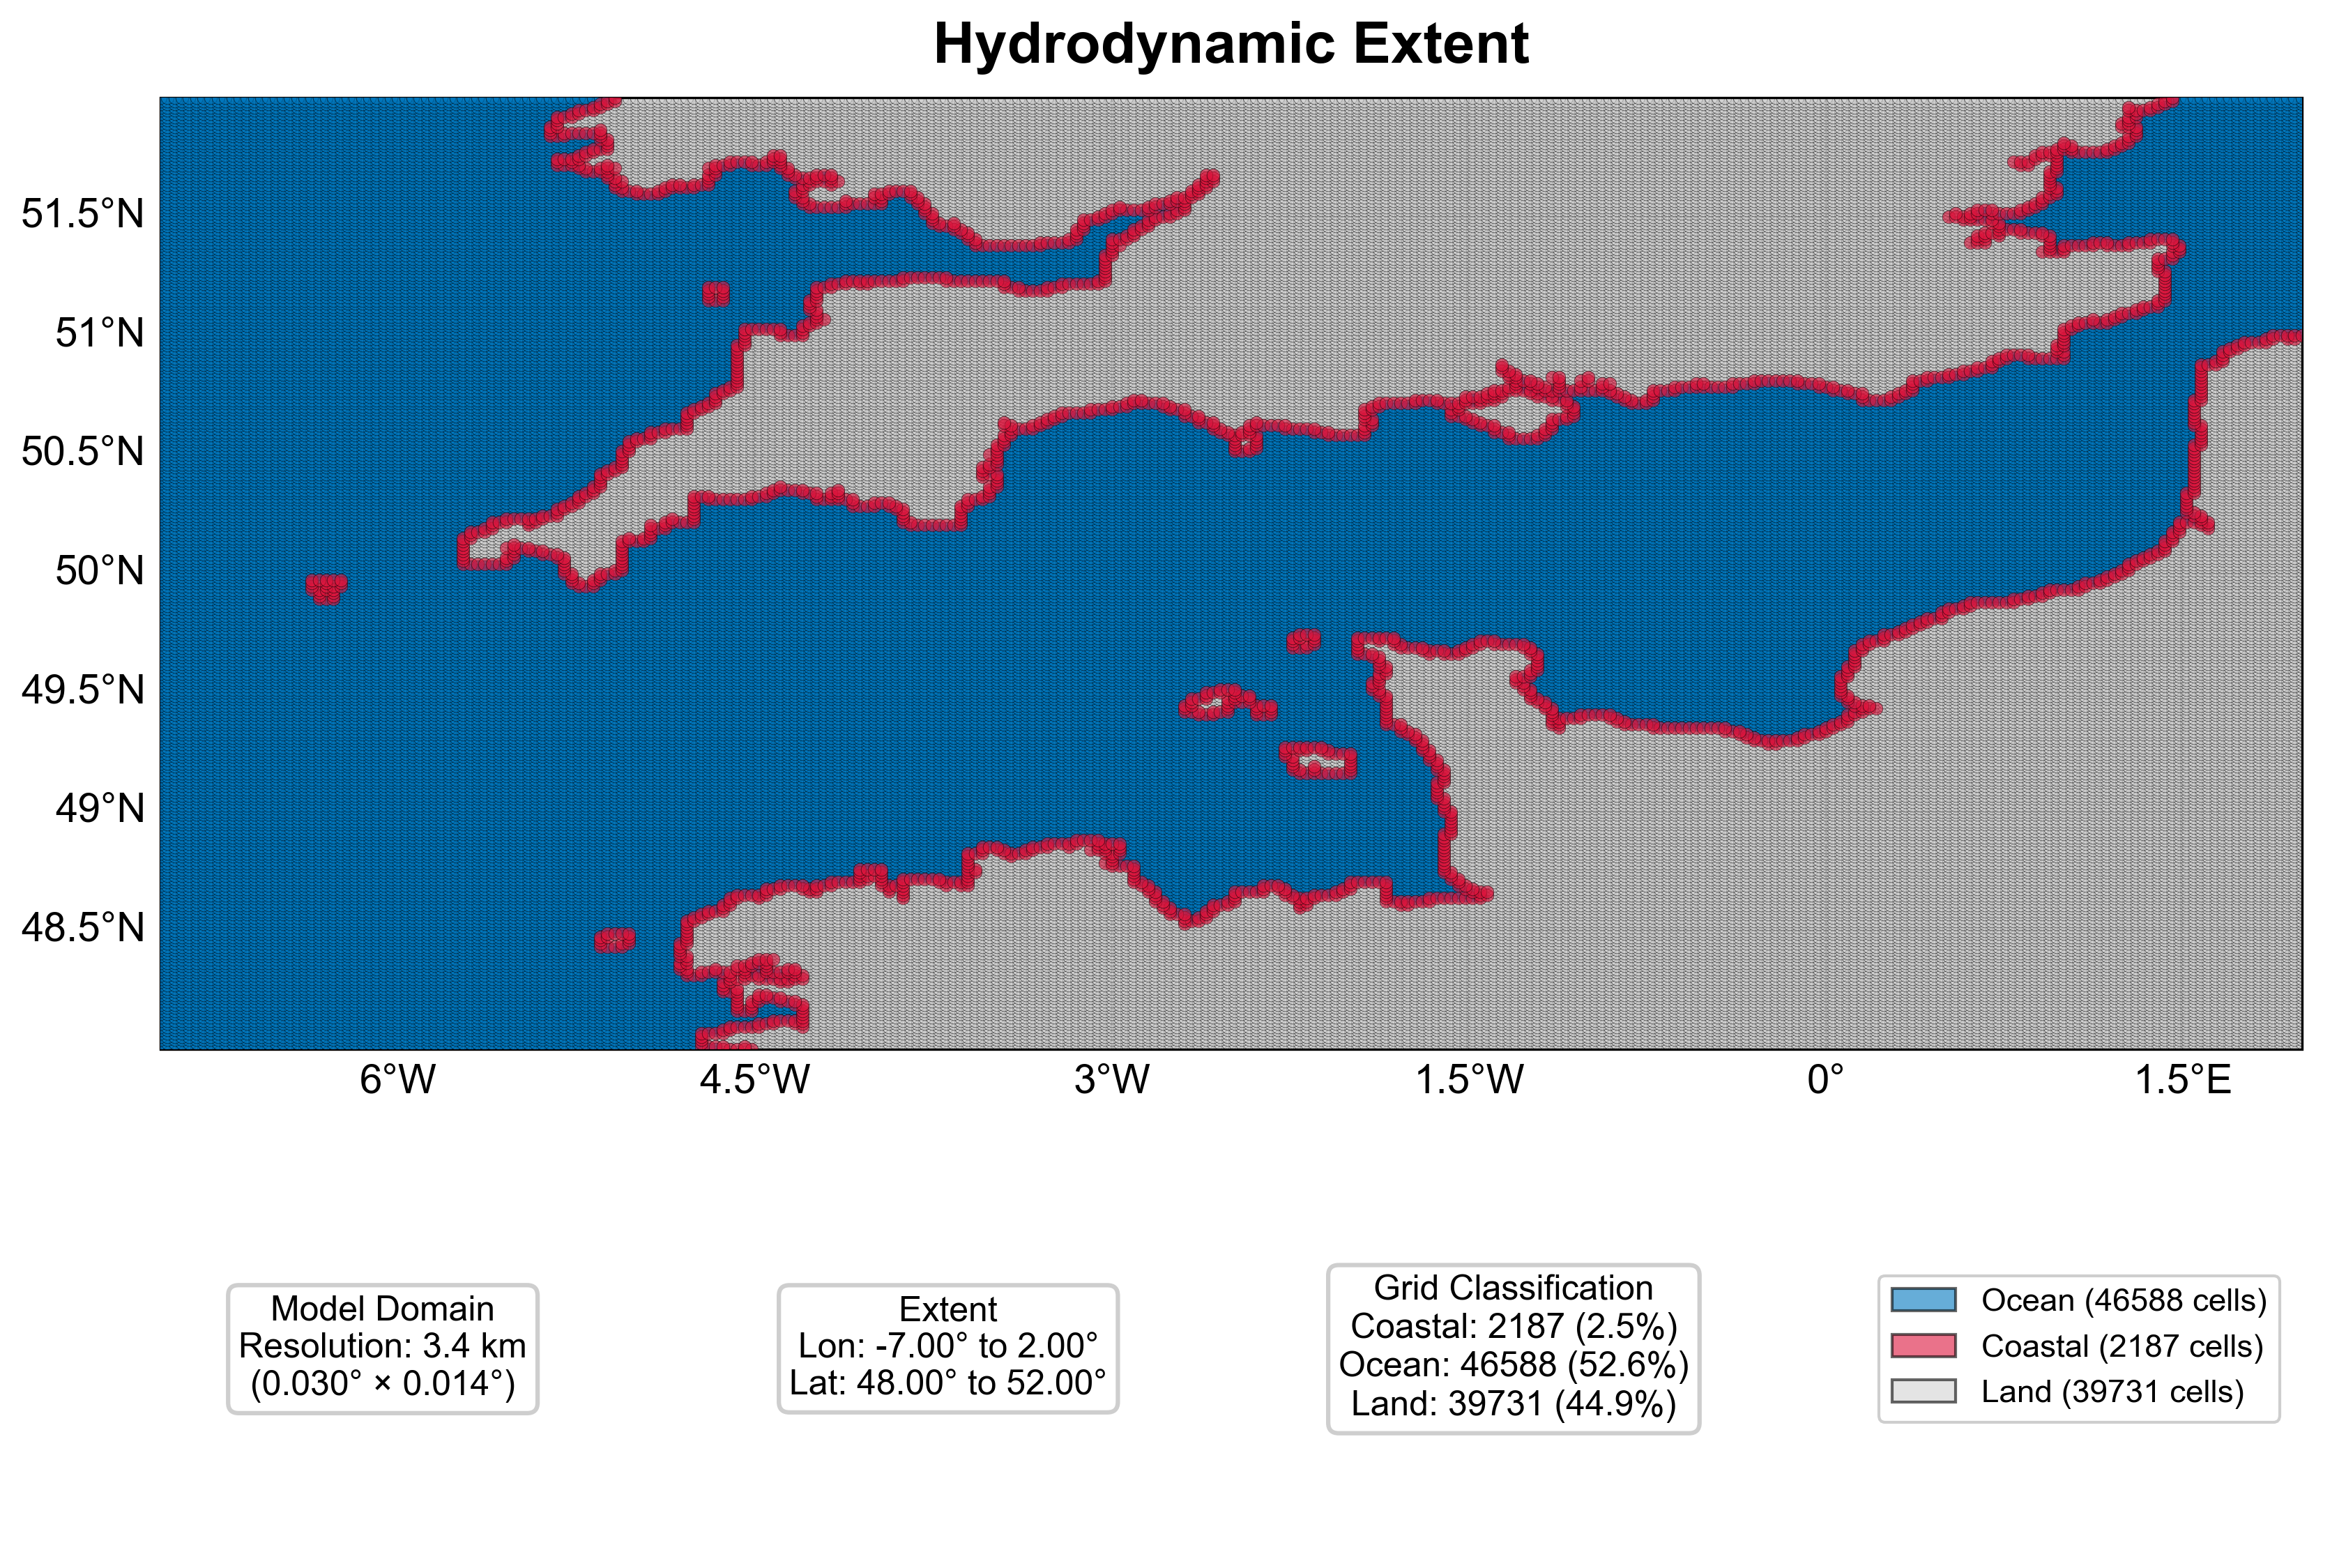


Save domain map? (yes/no):  no


Species Occurrence Data Cleaning Options



  The species occurrence data can be filtered based on your habitat preferences:
  
  Option 1: Coastal
    - This filters data to coastal habitats only and removes occurrences on land and offshore
    - This option is appropriate for littoral and infralittoral settings
  
  Option 2: Ocean
    - This filters data to all ocean occurrences (coastal and offshore)
      and removes occurrences on land
    - This option is appropriate for offshore and mixed (coastal & offshore) settings
  
  Option 3: None
    - This uses your data exactly as provided
    - This option is appropriate for pre-cleaned data




Choose habitat filtering (1/2/3):  1



Selected: Coastal filtering




Coastal Filtering



  Model resolution: 3.4 km
  Coastal zone: ~10.1 km total. Applies a 1 cell buffer landward and seaward for intertidal zone.
  Keeps species within ~3× grid spacing.




- - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - 
  Filtering Results
- - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - 
    Original occurrences: 2261
    After filtering: 2088
    Removed: 173 (7.7%)
- - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - 




Species Occurrence Data: Sample Size Validation


patella vulgata: 2088 records

- - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - 
  Summary
- - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - 
    Adequate sample size: 1/1 (100.0%)
    Low sample size: 0
    No records found: 0
- - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - 

Validation Passed
1 species have adequate sample sizes for analysis



Save filtered species data to CSV? (yes/no):  no


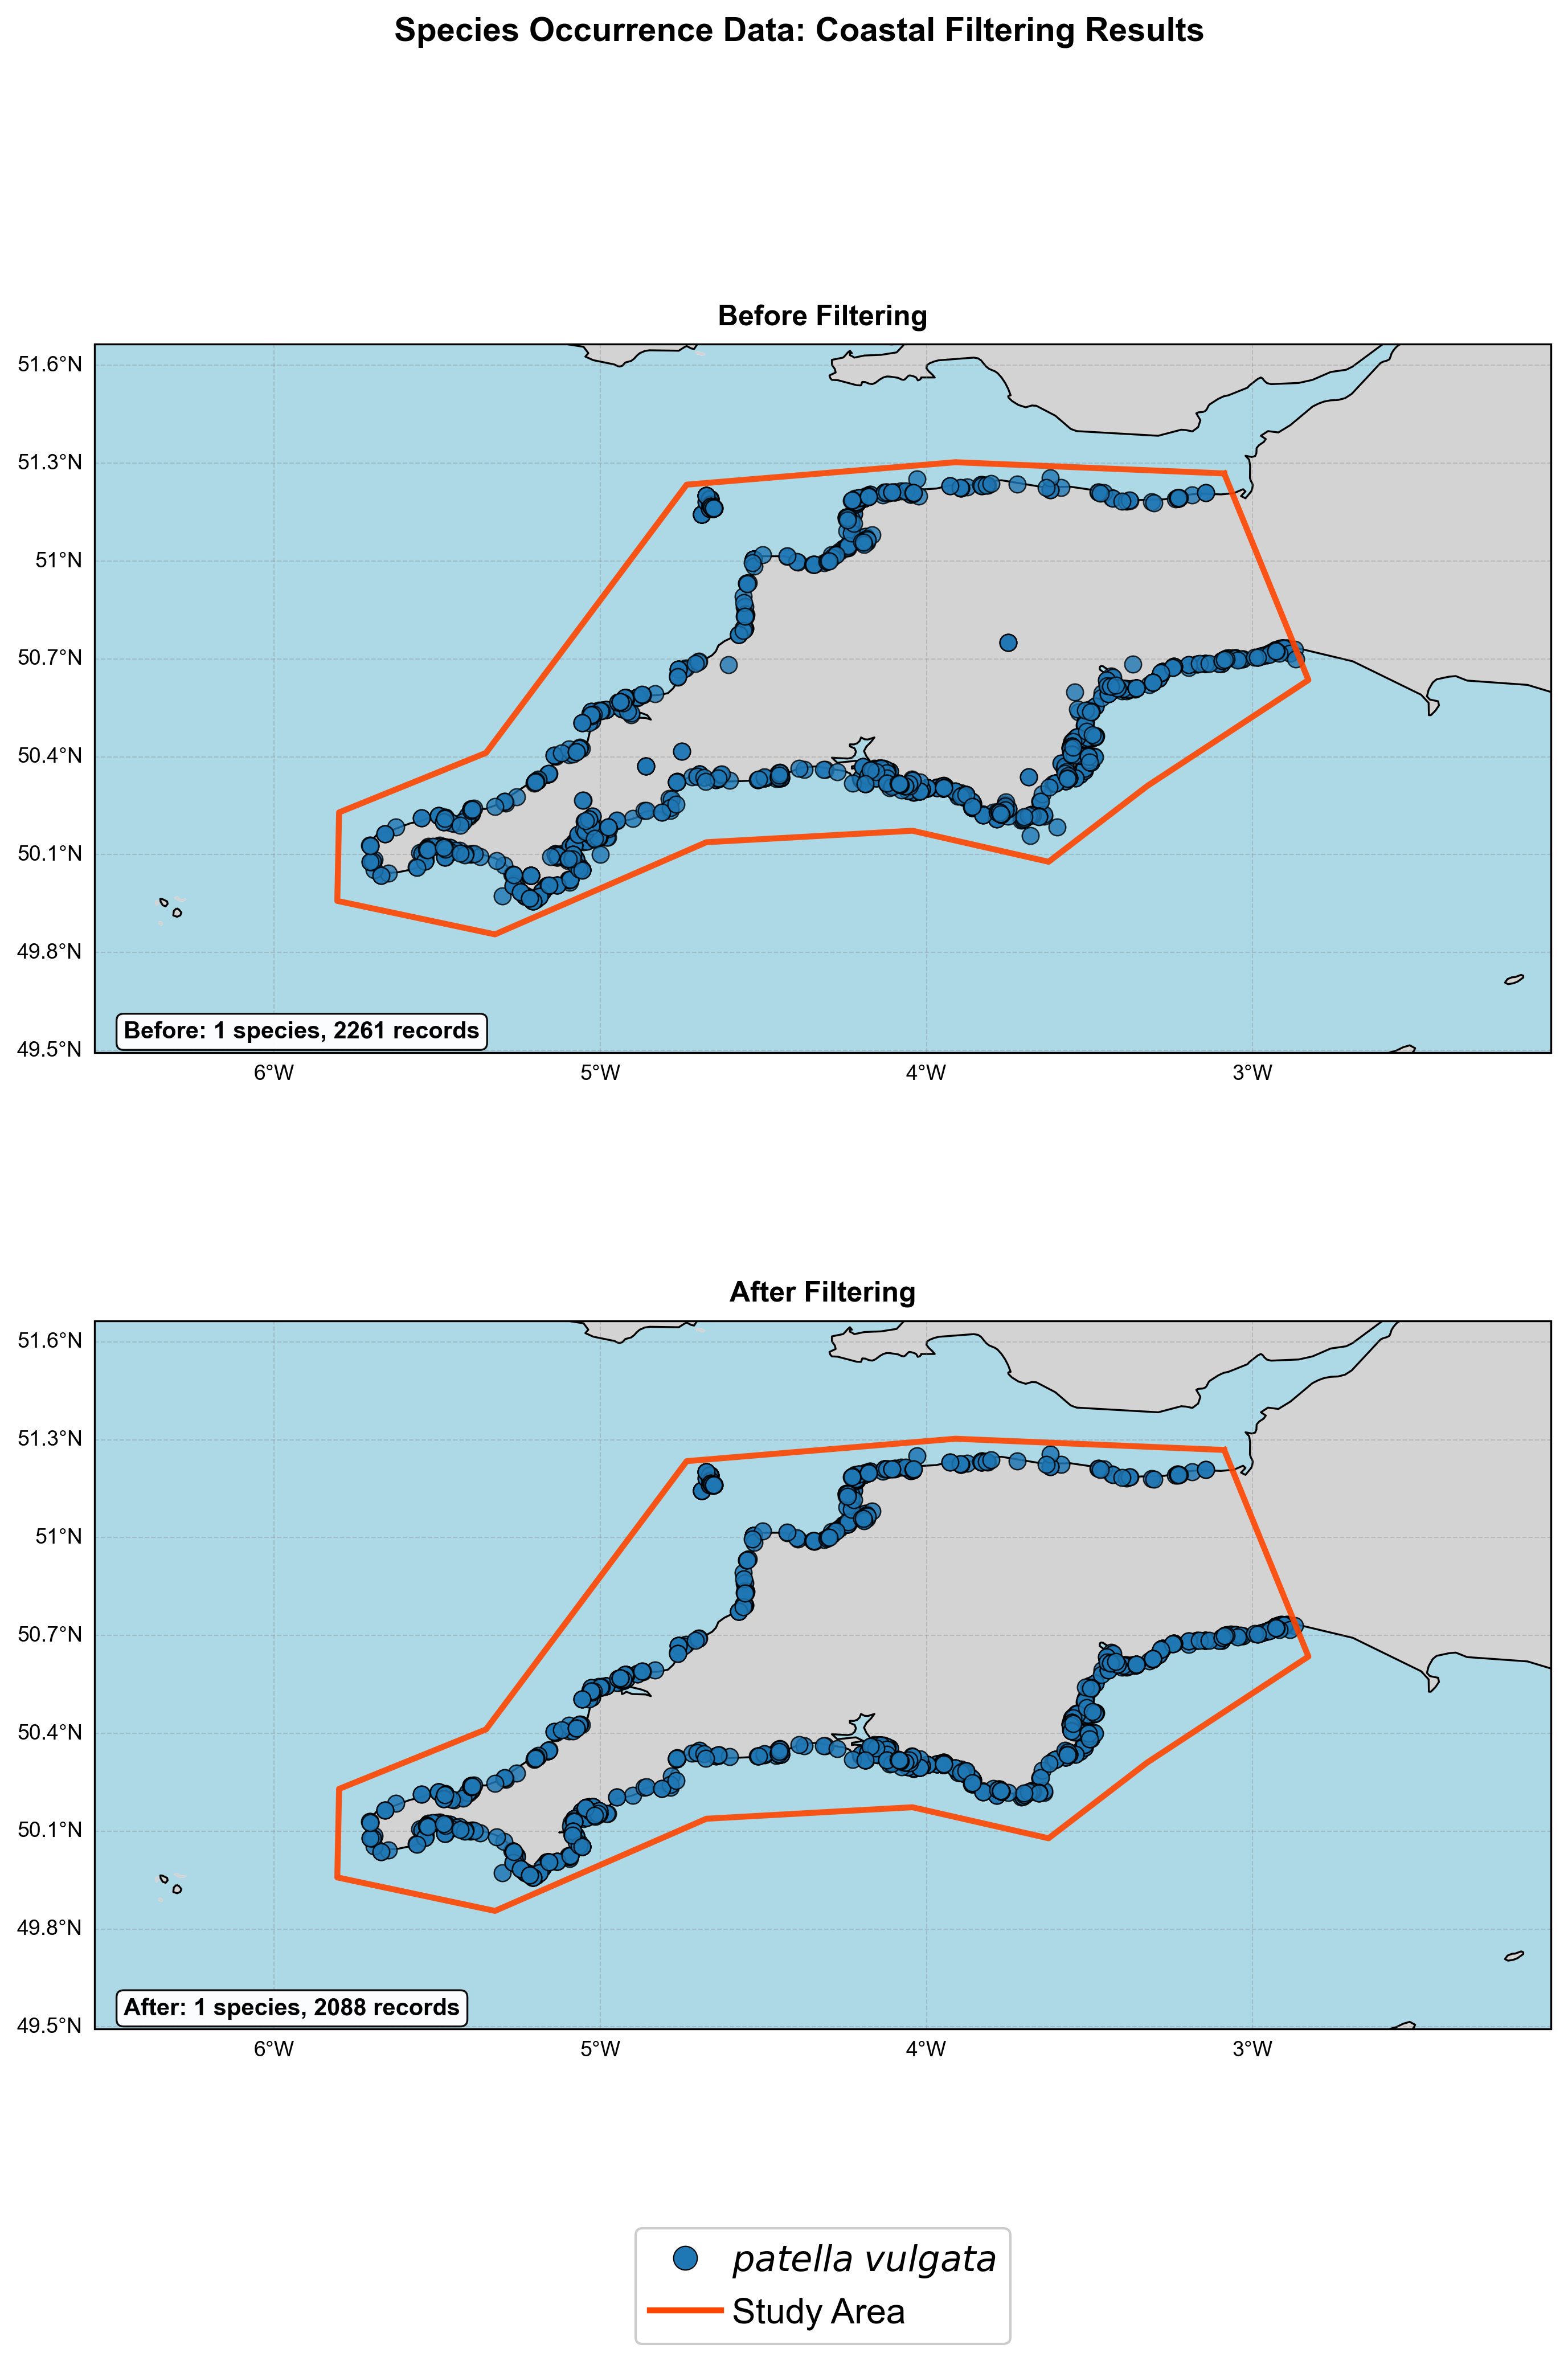


Save species map? (yes/no):  no


In [9]:
# Step 2: Download and clean species occurrence data

clean_spp, spp_params, landmask, coastalmask, lonarray, latarray = spp_occ(
    hydro_data, species_traits_path
)

---

## Step 3: Release and Settlement Setup

This step maps the species occurrence data onto the hydrodynamic model grid to create release sites (where particles start) and settlement sites (where particles can end up). It also creates the OceanParcels fieldset that will drive the particle simulation and sets up reflective boundaries to prevent particles from getting stuck on land.

In Manual Mode, this step uses four functions. First, `setup_release_settlement()` sets up the release and settlement sites. Then, `create_fieldset()` builds the OceanParcels fieldset from your hydrodynamic data. Next, `create_pset()` creates the particle set and prompts you for your release preferences. Finally, `create_custom_kernels()` defines the rules governing how particles behave (advection by currents, random diffusion and boundary interactions).

### What ComCon Will Ask You

#### Release and Settlement Strategy
- For release sites choose Option 2: Species-specific habitat (based on GBIF data)
- For settlement sites choose Option 2: Species-specific habitat (same as release data)

In this example, we will release and settle particles only where the species is currently recorded.


#### Release interval
- Choose weekly

Weekly releases capture temporal variation in ocean current conditions throughout the spawning season, ensuring that larvae experience a representative range of hydrodynamic conditions whilst still keeping the total particle count manageable.

#### Number of Particles
- Go with the default of 100

In a realistic simulation you will want to set the particle number much higher, e.g. 1000–10000. This does not represent the actual number of larvae being released but rather the resolution at which you are sampling possible dispersal pathways. Think of it like sample size. By increasing the number of particles, you increase the likelihood of capturing rare but important long-distance connections and produce more stable, reproducible connectivity estimates. For this example, 100 is sufficient to demonstrate the workflow and see general patterns.


#### Horizontal Diffusivity
- Go with the default of 1 m²/s

This is representative of standard small-scale random motion caused by turbulence in marine systems

ComCon will display a summary showing how many release and settlement sites were created. It will also create the OceanParcels fieldset (the velocity field used to advect particles) and set up reflective boundaries to prevent particles from getting stuck on land.


---

> **Note:** Here there are brackets around the input variables `(meshgrid, release grids...)`. This is only added as the number of parameters is split across two lines and it tells Python to read them as one statement.  

In [12]:
# Step 3a: Set up release and settlement grids

(meshgrid, release_grids, settlement_grids, full_grid_df, grid_ids, coastal_grid, coastal_grid_df,
 coastal_grid_filtered, grid_df_for_mapping) = setup_release_settlement(
            coastalmask, landmask, clean_spp, spp_params, lonarray, latarray)

Propagule Release Strategy



  Choose where particles should be released from.
  
  You can use the occurrence data from step 2, upload a different dataset or release from everywhere in your study area.
  
  Option 1: All sites in the study area
    - Release particles from all coastal sites in your study area
    - Does not use species occurrence data
    - This is suitable for assessing maximum dispersal scenarios or for data-poor scenarios
    - Total release sites: 423
  
  Option 2: Species-specific habitat (based on GBIF data)
    - Release particles only from species-specific suitable habitat
    - This is suitable for trait-based analysis
    - Uses: Species distributions from GBIF data
    - Total unique release sites: 221
    - Sum across 1 species: 221 (includes shared sites)
  
  Option 3: Custom species occurrence data
    - Upload your own species occurrence or habitat suitability data (CSV format)
    - This can be a different CSV file from the data loaded in step 2
    - Required columns: species,


Choose release strategy (1/2/3):  2


Created release grids for 1 species
Total unique release sites: 221




Propagule Settlement Strategy



  Choose where particles can settle.
  
  You can use the same data as for release, upload a different dataset
  or allow settlement everywhere in your study area.
  
  Option 1: All sites in the study area
    - Particles can settle anywhere in your study area
    - Does not use species occurrence data
    - This is suitable for assessing maximum dispersal scenarios or for data-poor scenarios
    - Total settlement sites: 423
  
  Option 2: Species-specific habitat (same as release data)
    - Particles can only settle in suitable habitat for each species
    - This is suitable for trait-based analysis
    - Uses: GBIF data from step 2
    - Total unique settlement sites: 221
    - Sum across 1 species: 221 (includes shared sites)
  
  Option 3: Custom species occurrence data
    - Upload your own species occurrence or habitat suitability data (CSV format)
    - This can be a different CSV file from the release site file
    - Required columns: species, latitude, longitude
    - This


Choose settlement strategy (1/2/3):  2


Created settlement grids for 1 species



Do you want to save the meshgrid data to a CSV file? (yes/no):  no

Do you want to save the release grid points to CSV files? (yes/no):  no

Do you want to save the settlement grid points to CSV files? (yes/no):  no


Now create the OceanParcels fieldset. This converts your hydrodynamic data into the velocity field that OceanParcels will use to advect (transport) particles. It also calculates reflective boundary vectors from the land mask so that particles move away from the coastline rather than getting stranded on land.

In [13]:
# Step 3b: Create OceanParcels fieldset

fieldset = create_fieldset(hydro_data, landmask, grid_ids)

Now create the particle set. This is where you configure how many particles to release, how often and with what diffusivity. A particle set is simply a collection of virtual particles with defined starting positions, release timing and behavioural rules.

Here, as noted above, choose:

- A **weekly** release interval
- The default of **100** particles to release per site and release interval
- The default of **1 m²/s**

In [14]:
# Step 3c: Create particle set

pset, adjusted_runtime, interval, repeatdt = create_pset(
    fieldset, meshgrid, runtime)

Release Strategy


Particles can be released at regular intervals over the duration of a species' spawning window.



Enter release interval ('daily', 'weekly', 'biweekly', 'monthly', or custom days) [default: weekly]:  weekly



- - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - 
  Release Settings
- - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - 
    Release interval: 7 days
    Number of release cohorts: 19
    Adjusted runtime: 133 days to fit all release cohorts
- - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - 




Number of Particles


Specify the number of particles to release per location per release cohort.

Example: If you enter 100:
Per location, per cohort: 100 particles will be released
Per location, total particles released: 100 × 19 = 1900 particles
All locations, total particles released: 419900 particles



Enter the number of particles per location per cohort [default: 100]:  100



- - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - 
  The Particle Setup
- - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - 
    Release cohorts: 19
    Interval: Every 7 days
    Release locations: 221
    Particles per location per cohort: 100
    Total particles per location: 1900
    Total particles: 419900
    Adjusted runtime: 133 days
- - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - 



Proceed with these settings? (yes/no):  yes



This package allows you to add a horizontal diffusivity value.

Horizontal diffusivity represents small-scale random motion caused by turbulence and applies evenly to all 
particles in the simulation.



Enter horizontal diffusivity (kh) in m²/s [default: 1]:  1


Finally, create the particle behaviour kernels. These define the rules that govern how each particle moves at every timestep.

In [15]:
# Step 3d: Create particle behaviour kernels

kernels = create_custom_kernels(pset)

---

## Step 4: Running the Simulation

This is the computationally intensive step. Using the `execute_simulation()` function, ComCon tracks all particles through the ocean current field over the full simulation period using OceanParcels.

### What ComCon Will Ask You

#### Output path
- Provide a file path and name for the simulation output

The raw simulation output will be saved as a .zarr file (a format for storing large array data efficiently).

#### Output frequency
- Choose 24 hours

Output frequency controls how often particle positions are recorded during the simulation. The default of 24 hours is fine for most analyses. It keeps file sizes manageable while providing daily position data. Higher frequency (e.g., 6 hours) gives more temporal detail but produces larger files.

#### Time step
- Choose the default of 60 minutes

This is the interval at which particle positions are calculated during the simulation. The default of 60 minutes provides a good balance between accuracy and speed. Smaller timesteps are more accurate but slower.

#### Memory check
ComCon will automatically check your system's available RAM and adjust processing chunk sizes accordingly. You do not need to do anything here. This is just informational. 

ComCon will then display a summary of simulation settings (runtime, output frequency, time step) and begin running the OceanParcels simulation with a progress bar. 

> **Tip:** If the simulation runs slowly or you experience memory issues, try reducing the number of particles or the study area extent. See the Troubleshooting section in the User Guide.

In [16]:
# Step 4c: Run simulation
output_path, traj = execute_simulation(
    pset, kernels, adjusted_runtime, interval
)

Setting up the Simulation



Enter the output path and file name to save the simulation output:  D:\Python_Code\comcon_distribution\outputs\single_species_manual


Output Frequency



  In a particle simulation, particles are advected at regular timesteps (e.g. every hour).
  You can save output less frequently than the simulation timestep to reduce file size.
  
  For example: Timestep = 1 hour, Output frequency = 6 hours.
    - Higher frequency = more temporal detail but larger files
    - Lower frequency = less detail but smaller files
    - Higher timestep = more detail but slower simulation runtime
    - Lower timestep = less detail but faster simulation runtime



Enter output frequency in hours [default: 24]:  
Enter time step (dt) in minutes [default: 60]:  


System Memory Check



  This package checks your available RAM to optimise processing.
  Large simulations generate significant data that must fit in memory.
  The package will automatically adjust chunk sizes to prevent crashes.



System Memory:
 - Total: 63.6 GB
 - Available: 33.8 GB
 - Used: 46.9%

Memory Calculation:
  - Simulation length: 133 days
  - Output timesteps: 133
  - Memory per 1000 trajectories: 0.02 GB

System: 64 GB total RAM, 33.8 GB currently available
Processing will use chunks of 10000 trajectories to prevent memory issues.

- - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - 
  Simulation settings
- - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - 
    Runtime: 133 days
    Output frequency: 24 hours
    Time step: 60 minutes
- - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - 
Running OceanParcels simulation......
INFO: Output files are stored in D:\Python_Code\comcon_distribution\outputs\single_species_manual.zarr.


INFO:Output files are stored in D:\Python_Code\comcon_distribution\outputs\single_species_manual.zarr.


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 11491200.0/11491200.0 [23:37<00:00, 8104.99it/s]

Processing simulation results...

Output file size: 0.31 GB
Using memory-safe chunked loading (10000 trajectories per chunk)
Loading simulation results...
Opening zarr dataset...

- - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - 
  Dataset properties
- - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - 
    Trajectories: 419900
    Time steps: 133
    The dataset will be imported in chunks of 10000 trajectories
- - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - 
Importing chunk 1/42 (10000 trajectories)...
Chunk 1...
Importing chunk 2/42 (10000 trajectories)...
Chunk 2...
Importing chunk 3/42 (10000 trajectories)...
Chunk 3...
Importing chu

---

## Step 5: Post-Processing

The raw simulation output contains all particle trajectories regardless of biological constraints. Post-processing, our other most time-intensive step of this workflow, applies three sequential filters to extract only the trajectories that are biologically relevant for *P. vulgata* using the `post_process()` function:

1. **Spawning filter:** Retains only particles released during the spawning window (Oct–Jan).
2. **PLD filter:** Crops each trajectory to the species' pelagic larval duration (2–10 days) and checks whether the particle reached suitable settlement habitat within that time
3. **Habitat filter:** Confirms particles were released from suitable habitat for the species

### What ComCon Will Ask You

**Settlement buffer:**
- Choose a buffer of 1 cell

ComCon will ask for a buffer size (in grid cells) around settlement sites.  A buffer of 1 allows particles to settle if they are within one grid cell of a known settlement location, accounting for the fact that grid cells may not perfectly align with actual habitat.

After filtering, ComCon will display a summary showing how many trajectories passed each filter. You will typically see a large reduction. This is expected. Many particles will be released outside the spawning window (removed by filter 1), or will not reach settlement habitat within the PLD (removed by filter 2).

---

In [17]:
# Step 5: Post-process trajectories

final_processed, buffer = post_process(
    traj, traits, release_grids, settlement_grids, grid_ids
)

Starting Post-processing



2. Applying spawning seasonality filter...
Species assignment...

Assigning species to trajectories...

Creating unique trajectory IDs for 1 species...
Species assignment...
   patella_vulgata: 397800 trajectories
Species assignment complete: 1 species with trajectories.

3. Applying day-wise PLD filter...


Enter buffer size around settlement sites [default: 1 adjacent grid cell]:  [default: 1]:  1



Processing PLD filter for patella vulgata...
  PLD window: 2 - 10 days
  Settlement sites: 221 (with buffer: 1063)
  212771 successful trajectories
  Successful trajectories per day: day 2: 145101, day 3: 25444, day 4: 12406, day 5: 8517, day 6: 6438, day 7: 4086, day 8: 4392, day 9: 2997, day 10: 3390

4. Applying release location filter...
  patella_vulgata: 212771 trajectories from release sites

- - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - 
  Post-processing Summary
- - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - 
    patella_vulgata: 212771 successful trajectories from 18 release cohorts
    
    Total successful trajectories: 212771
- - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - 


---

## Step 6: Connectivity Analysis using Type 1: Connectivity Metrics

This is where we address our research question: What are the dispersal characteristics of *P. vulgata* along the southern English coast? 

Type 1 analysis provides the fundamental descriptive metrics of larval dispersal: How many larvae settle, how far they travel, and how much local recruitment occurs. These metrics form the baseline for understanding any species' connectivity before moving on to more complex network or sensitivity analyses.

In Manual Mode, you have two options for running analyses. You can use the `post_analysis()` wrapper function, which gives you the same interactive prompts as Interactive Mode (scope selection, which analysis types to run, etc.). 

Alternatively, you can call the individual analysis functions directly, which is useful when you only want to run one of the analyses. 

Here, we will use the direct approach and call `calculate_connectivity_metrics()` followed by `display_metrics_table()` to run and display the Type 1 analysis.


### What ComCon Will Ask You

**Analysis scope:**
- Choose Option 2: Per-species only

Since we only have one species, the community level and per-species analyses are identical.

**Which analyses to run:**
- Select **Yes** for Type 1 (Connectivity Metrics)
- Select **No** for Type 2 and Type 3 for now.

We will cover these in Vignettes 2 and 3

### Understanding the Type 1 Output

ComCon will display a table of connectivity metrics. Here is what each metric tells you:

|Metric   | What It Means |
|:---------|:---------------|
| **Released** | The total number of particles released during the species' spawning window across all release sites and cohorts. |
| **Settled** | The number of released particles that successfully reached suitable habitat within their PLD window. |
| **Settlement rate** | The proportion of released particles that successfully settle. Calculated as: settled ÷ released × 100. Rates vary widely between species and study areas depending on current patterns, habitat availability and PLD. |
| **Mortality rate** | The proportion of released particles that fail to settle. Calculated as: 100 − settlement rate. Note that this represents computational mortality (particles that did not encounter suitable habitat within their PLD window), not realised mortality which is dependent on a range of additional biological factors not accounted for in the model such as competition for resources, predation and environmental stochasticity. |
| **Local recruitment rate** | The proportion of settled particles that return to within the settlement buffer of their own release site. High values indicate populations that may be more self-sustaining; low values suggest greater dependence on larval supply from other sites. |
| **Min/Mean/Max net displacement** | The straight-line (Haversine) distance from each particle's release point to its settlement point. This measures where larvae end up relative to where they started, not the total path they travelled. A value of 0.0 km means the particle settled at or very near its release site. |
| **Min/Mean/Max PLD** | The realised time each particle spent in the water column before settling. This may be shorter than the species' maximum PLD if suitable habitat is encountered quickly. |

---

In [4]:
# Step 6: Calculate Type 1 connectivity metrics

metrics = calculate_connectivity_metrics(
    final_processed, release_grids, settlement_grids, traits, traj, grid_ids=grid_ids
)

Species: patella vulgata


Released: 397800 trajectories
Settled: 174291 trajectories
Settlement rate: 43.8%
Mortality rate: 56.2%
Local recruitment rate: 19.1%, within 1-cell buffer of release site (33223 trajectories)
Min net displacement: 0.0 km
Mean net displacement: 9.6 km
Max net displacement: 88.2 km
Min PLD: 2.0 days
Mean PLD: 2.8 days
Max PLD: 10.0 days


### Interpreting the Results for *P. vulgata*

> Note: The results shown in this vignette will not match your results exactly because the model includes stochastic particle movement to represent small-scale turbulence and natural variability in larval transport. As a result, trajectories differ slightly between simulation runs, even under identical settings.

**Settlement rate:** Settlement rates vary widely depending on a range of biophysical factors including the density of suitable habitat in your study area, local current patterns and coastline geometry. There is no simple relationship between PLD length and settlement success. Your results reflect the specific combination of oceanography and habitat distribution in your study domain. 

**Local recruitment:** For a short PLD species, we might expect a relatively high proportion of settled particles to have returned to or near their release site compared to species with longer PLDs. However, this also greatly depends on local current patterns and cannot be generalised across species and areas.

**Net displacement:** Short PLDs generally limit both the maximum and mean distance larvae travel, relative to  species with longer PLDs. 

**PLD:** The PLD values reported in the output table are the actual time each settled particle spent in the water column (realised PLD), not the species' literature value. If suitable habitat is encountered before the end of the PLD window, particles settle earlier. In habitat-rich areas, mean realised PLDs may be considerably shorter than the maximum.

What do your results show? Do they match general predictions or are there surprises? 

> Note: These results are based on a low-resolution example (100 particles per site per release event). For robust scientific conclusions, you would want to increase particle numbers and validate against field observations. Type 1 metrics estimate potential connectivity based on physical transport. They do not account for post-settlement survival or other biological processes.

---

## Summary

You have now completed the same single-species connectivity analysis as Vignette 1.1, but using Manual Mode. The key differences were:

1. **Explicit function calls** rather than `workflow_step()`. You called `params()`, `spp_occ()`, `setup_release_settlement()`, etc. directly
2. **Direct analysis access**. You called `calculate_connectivity_metrics()` and `display_metrics_table()` instead of choosing from an interactive menu

The results are identical to what Interactive Mode produces because the same underlying functions are used.

### What Next?

- **Vignette 1.3** demonstrates the same analysis using **Automatic Mode**, which collects all parameters upfront and then runs the entire workflow hands-off.
- **Vignette 2** extends this to a multi-species analysis and introduces **Type 2: Network Analysis**. This identifies connectivity hotspots — the specific sites that play the most important roles in maintaining the dispersal network.
- **Vignette 3** demonstrates **Type 3: Trait Sensitivity Analysis**, testing how robust your results are to uncertainty in species trait data.

Vignettes 2 and 3 use Manual Mode, so the function-calling approach you have learned here carries directly over.